## ЗАДАНИЕ 1. Q-learning vs Dyna-Q (Discrete/Discrete)

In [4]:
import gymnasium as gym
import numpy as np
import time
import matplotlib.pyplot as plt
from collections import defaultdict
import random
import os

import warnings
warnings.filterwarnings('ignore')

In [5]:
def train_q_dyna(env_name="Taxi-v3", seeds=[1, 2], N_PLANNING=[0, 100], episodes=500, render_every=50):
    results = {f"Q-learn (N={n})": [] for n in N_PLANNING}

    for n_plan in N_PLANNING:
        label = f"Q-learn (N={n_plan})" if n_plan == 0 else f"Dyna-Q (N={n_plan})"
        seed_rewards = []

        for seed in seeds:
            random.seed(seed)
            np.random.seed(seed)
            env = gym.make(env_name)

            Q = defaultdict(lambda: np.zeros(env.action_space.n))
            # state -> action -> (reward, next_state, done)
            model = defaultdict(dict)
            episode_rewards = []

            for ep in range(episodes):
                state, _ = env.reset(seed=seed)
                total_r = 0
                done = False
                while not done:
                    eps = max(0.01, 0.3 * (0.99 ** ep))
                    action = env.action_space.sample(
                    ) if random.random() < eps else np.argmax(Q[state])
                    next_state, reward, term, trunc, _ = env.step(action)
                    done = term or trunc
                    total_r += reward

                    # Q-update
                    Q[state][action] = Q[state][action] + 0.3 * \
                        (reward + 0.99 *
                         np.max(Q[next_state]) * (1-done) - Q[state][action])

                    # Model update
                    model[state][action] = (reward, next_state, done)

                    # Dyna Planning
                    for _ in range(n_plan):
                        s_m = random.choice(list(model.keys()))
                        a_m = random.choice(list(model[s_m].keys()))
                        r_m, ns_m, d_m = model[s_m][a_m]
                        Q[s_m][a_m] = Q[s_m][a_m] + 0.3 * \
                            (r_m + 0.99 * np.max(Q[ns_m])
                             * (1-d_m) - Q[s_m][a_m])

                    state = next_state
                episode_rewards.append(total_r)
            seed_rewards.append(episode_rewards)
        results[label] = seed_rewards
    return results

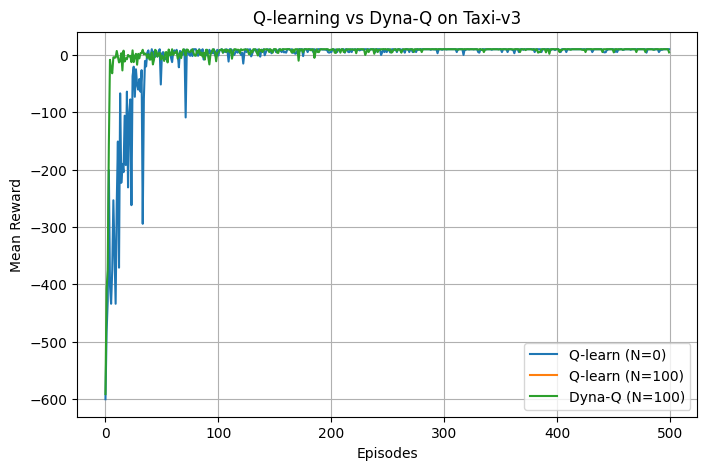

In [6]:
# Запуск и построение
res = train_q_dyna()
plt.figure(figsize=(8, 5))
for label, seeds_data in res.items():
    mean_r = np.mean(seeds_data, axis=0)
    plt.plot(mean_r, label=label)
plt.xlabel("Episodes")
plt.ylabel("Mean Reward")
plt.title("Q-learning vs Dyna-Q on Taxi-v3")
plt.legend()
plt.grid()
plt.savefig("results/q_vs_dyna.png")
plt.show()

---
## ЗАДАНИЕ 2. PPO vs PPO + World Model (Continuous/Discrete)

In [16]:
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions.categorical import Categorical
from torch.distributions.normal import Normal
import os
import random
import time
from pyvirtualdisplay import Display
from IPython.display import HTML
from base64 import b64encode

# ============================================================================
# Утилиты
# ============================================================================

def record_video(env, policy=None, duration=1000):
    """Функция для записи видео"""
    frames = []
    state, _ = env.reset()
    for _ in range(duration):
        if policy:
            action = policy(state)
        else:
            action = env.action_space.sample()
        frame = env.render()
        frames.append(frame)
        state, _, terminated, truncated, _ = env.step(action)
        if terminated or truncated:
            break
    env.close()
    return frames

def show_progress(rewards_batch, log, step, global_steps, reward_range=None):
    """Функция для отображения прогресса обучения"""
    if reward_range is None:
        reward_range = [-990, +10]
    mean_reward = np.mean(rewards_batch)
    log.append([mean_reward])
    global_steps.append(step)
    
    from IPython.display import clear_output
    import matplotlib.pyplot as plt
    clear_output(True)
    plt.figure(figsize=[8, 4])
    plt.subplot(1, 2, 1)
    plt.plot(global_steps, list(zip(*log))[0], label='Mean rewards')
    plt.legend(loc=4)
    plt.grid()
    plt.show()

# ============================================================================
# Архитектура моделей
# ============================================================================

def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    """Инициализация слоёв с ортогональной инициализацией"""
    torch.nn.init.orthogonal_(layer.weight, std)
    torch.nn.init.constant_(layer.bias, bias_const)
    return layer

class WorldModel(nn.Module):
    """Модель мира: предсказывает (reward, next_obs, done) по (obs, action)"""
    def __init__(self, obs_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            layer_init(nn.Linear(obs_dim + action_dim, 128)),
            nn.SiLU(),
            layer_init(nn.Linear(128, 64)),
            nn.SiLU()
        )
        self.reward_net = nn.Sequential(
            layer_init(nn.Linear(64, 1), std=0.01)
        )
        self.next_obs_net = nn.Sequential(
            layer_init(nn.Linear(64, obs_dim), std=0.01)
        )
        self.done_net = nn.Sequential(
            layer_init(nn.Linear(64, 1), std=0.01)
        )

    def forward(self, obs, action):
        x = torch.cat([obs, action], dim=-1)
        x = self.net(x)
        reward = self.reward_net(x)
        next_obs = self.next_obs_net(x)
        done = torch.sigmoid(self.done_net(x))
        return reward, next_obs, done

class Agent(nn.Module):
    """PPO агент с актором и критиком"""
    def __init__(self, envs, continuous_action=False):
        super().__init__()
        self.continuous_action = continuous_action
        
        # Критик
        self.critic = nn.Sequential(
            layer_init(nn.Linear(np.array(envs.single_observation_space.shape).prod(), 64)),
            nn.Tanh(),
            layer_init(nn.Linear(64, 64)),
            nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0),
        )
        
        # Актор
        if self.continuous_action:
            self.actor_mean = nn.Sequential(
                layer_init(nn.Linear(np.array(envs.single_observation_space.shape).prod(), 64)),
                nn.Tanh(),
                layer_init(nn.Linear(64, 64)),
                nn.Tanh(),
                layer_init(nn.Linear(64, np.prod(envs.single_action_space.shape)), std=0.01),
            )
            self.actor_logstd = nn.Parameter(torch.zeros(1, np.prod(envs.single_action_space.shape)))
        else:
            self.actor = nn.Sequential(
                layer_init(nn.Linear(np.array(envs.single_observation_space.shape).prod(), 64)),
                nn.Tanh(),
                layer_init(nn.Linear(64, 64)),
                nn.Tanh(),
                layer_init(nn.Linear(64, envs.single_action_space.n), std=0.01),
            )

    def get_value(self, x):
        return self.critic(x)

    def get_action_and_value(self, x, action=None):
        if self.continuous_action:
            action_mean = self.actor_mean(x)
            action_logstd = self.actor_logstd.expand_as(action_mean)
            action_std = torch.exp(action_logstd)
            probs = Normal(action_mean, action_std)
            if action is None:
                action = probs.sample()
            return action, probs.log_prob(action).sum(1), probs.entropy().sum(1), self.critic(x)
        else:
            logits = self.actor(x)
            probs = Categorical(logits=logits)
            if action is None:
                action = probs.sample()
            return action, probs.log_prob(action), probs.entropy(), self.critic(x)

# ============================================================================
# Конфигурация
# ============================================================================

class Args:
    exp_name: str = "ppo_wm_exp"
    seed: int = 1
    torch_deterministic: bool = True
    cuda: bool = True

    # PPO параметры
    env_id: str = "InvertedPendulum-v5"
    continuous_actions: bool = True
    total_timesteps: int = 10_000_000
    learning_rate: float = 2.5e-3
    num_envs: int = 20
    num_steps: int = 64
    anneal_lr: bool = True
    gamma: float = 0.99
    gae_lambda: float = 0.95
    num_minibatches: int = 4
    update_epochs: int = 4
    norm_adv: bool = True
    clip_coef: float = 0.2
    clip_vloss: bool = True
    ent_coef: float = 0.01
    vf_coef: float = 0.5
    max_grad_norm: float = 0.5
    target_kl: float = None

    # World Model параметры
    model_based_learning: bool = True
    world_model_lr: float = 2.5e-3
    imagination_steps: int = 20
    world_model_updates: int = 8
    wm_batch_size: int = 128
    imagination_batch_size: int = 60
    img_update_epochs: int = 2
    image_train_iters: int = 2
    wm_warmup: int = 5  # Начать обучение в воображении после этого числа итераций

    # Вычисляемые параметры
    batch_size: int = 0
    minibatch_size: int = 0
    num_iterations: int = 0

# ============================================================================
# Основная функция обучения
# ============================================================================

def train():
    args = Args()
    args.batch_size = int(args.num_envs * args.num_steps)
    args.minibatch_size = int(args.batch_size // args.num_minibatches)
    args.num_iterations = args.total_timesteps // args.batch_size
    
    assert args.imagination_batch_size % args.num_envs == 0, \
        f"imagination_batch_size: {args.imagination_batch_size} должно делиться на num_envs {args.num_envs}"

    # Установка seed
    random.seed(args.seed)
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)
    torch.backends.cudnn.deterministic = args.torch_deterministic

    device = torch.device("cuda" if torch.cuda.is_available() and args.cuda else "cpu")

    # Создание среды
    def make_env(env_id, idx):
        def thunk():
            env = gym.make(env_id)
            env = gym.wrappers.RecordEpisodeStatistics(env)
            return env
        return thunk

    envs = gym.vector.SyncVectorEnv(
        [make_env(args.env_id, i) for i in range(args.num_envs)],
    )

    # Инициализация моделей
    agent = Agent(envs, continuous_action=args.continuous_actions).to(device)
    optimizer = optim.Adam(agent.parameters(), lr=args.learning_rate, eps=1e-5)
    
    world_model = WorldModel(
        int(np.prod(envs.single_observation_space.shape)),
        int(np.prod(envs.single_action_space.shape))
    ).to(device)
    world_optimizer = optim.Adam(world_model.parameters(), lr=args.world_model_lr)

    # Буферы для траекторий
    obs = torch.zeros((args.num_steps, args.num_envs) + envs.single_observation_space.shape).to(device)
    actions = torch.zeros((args.num_steps, args.num_envs) + envs.single_action_space.shape).to(device)
    logprobs = torch.zeros((args.num_steps, args.num_envs)).to(device)
    rewards = torch.zeros((args.num_steps, args.num_envs)).to(device)
    dones = torch.zeros((args.num_steps, args.num_envs)).to(device)
    values = torch.zeros((args.num_steps, args.num_envs)).to(device)

    # Буфер для обучения модели мира
    world_obs_buffer = []
    world_action_buffer = []
    world_reward_buffer = []
    world_next_obs_buffer = []
    world_done_buffer = []

    # Старт обучения
    global_step = 0
    start_time = time.time()
    next_obs, _ = envs.reset(seed=args.seed)
    next_obs = torch.Tensor(next_obs).to(device)
    next_done = torch.zeros(args.num_envs).to(device)

    train_rewards = []
    log_train_reward = []
    losses = []
    entropies = []
    global_steps = []

    for iteration in range(1, args.num_iterations + 1):
        # Annealing learning rate
        if args.anneal_lr:
            frac = 1.0 - (iteration - 1.0) / args.num_iterations
            lrnow = frac * args.learning_rate
            optimizer.param_groups[0]["lr"] = lrnow

        # Сбор данных из реальной среды
        for step in range(args.num_steps):
            global_step += args.num_envs
            obs[step] = next_obs
            dones[step] = next_done

            # Выбор действия
            with torch.no_grad():
                action, logprob, _, value = agent.get_action_and_value(next_obs)
                values[step] = value.flatten()
            actions[step] = action
            logprobs[step] = logprob

            # Шаг в среде
            next_obs_np, reward, terminations, truncations, infos = envs.step(action.cpu().numpy())
            np_next_done = np.logical_or(terminations, truncations)
            rewards[step] = torch.tensor(reward).to(device).view(-1)
            next_obs = torch.Tensor(next_obs_np).to(device)
            next_done = torch.Tensor(np_next_done).to(device)

            # Сохранение в буфер модели мира
            world_obs_buffer.append(next_obs.clone())
            world_action_buffer.append(action.clone())
            world_reward_buffer.append(torch.tensor(reward).to(device).view(-1))
            world_next_obs_buffer.append(next_obs.clone())
            world_done_buffer.append(torch.Tensor(np_next_done).to(device))

            # Логирование наград
            if "episode" in infos:
                ep_rewards = infos['episode']['r'] * np_next_done
                if np_next_done.sum() > 0:
                    train_rewards.append(ep_rewards.sum() / np_next_done.sum())

        # Обучение модели мира
        if args.model_based_learning and iteration > 1:
            # Конвертируем буферы в тензоры
            wm_obs = torch.stack(world_obs_buffer, dim=0)  # [T, num_envs, obs_dim]
            wm_actions = torch.stack(world_action_buffer, dim=0)  # [T, num_envs, action_dim]
            wm_rewards = torch.stack(world_reward_buffer, dim=0)  # [T, num_envs]
            wm_next_obs = torch.stack(world_next_obs_buffer, dim=0)  # [T, num_envs, obs_dim]
            wm_dones = torch.stack(world_done_buffer, dim=0)  # [T, num_envs]

            for _ in range(args.world_model_updates):
                # Сэмплирование батча
                total_transitions = wm_obs.shape[0] * args.num_envs
                idx = np.random.randint(0, total_transitions, args.wm_batch_size)
                
                # Преобразование индексов
                time_idx = idx // args.num_envs
                env_idx = idx % args.num_envs
                
                obs_batch = wm_obs[time_idx, env_idx].to(device)
                actions_batch = wm_actions[time_idx, env_idx].to(device)
                rewards_batch = wm_rewards[time_idx, env_idx].unsqueeze(1).float().to(device)
                next_obs_batch = wm_next_obs[time_idx, env_idx].to(device)
                dones_batch = wm_dones[time_idx, env_idx].unsqueeze(1).to(device)

                # Предсказания модели мира
                pred_rewards, pred_next_obs, pred_dones = world_model(obs_batch, actions_batch)

                # Потери
                reward_loss = nn.MSELoss()(pred_rewards, rewards_batch)
                obs_loss = nn.MSELoss()(pred_next_obs, next_obs_batch)
                done_loss = nn.BCELoss()(pred_dones, dones_batch.float())
                total_loss = reward_loss + obs_loss + done_loss

                # Обновление
                world_optimizer.zero_grad()
                total_loss.backward()
                world_optimizer.step()

        # Вычисление преимуществ (GAE) для реальных данных
        with torch.no_grad():
            next_value = agent.get_value(next_obs).reshape(1, -1)
            advantages = torch.zeros_like(rewards).to(device)
            lastgaelam = 0
            for t in reversed(range(args.num_steps)):
                if t == args.num_steps - 1:
                    nextnonterminal = 1.0 - next_done
                    nextvalues = next_value
                else:
                    nextnonterminal = 1.0 - dones[t + 1]
                    nextvalues = values[t + 1]
                delta = rewards[t] + args.gamma * nextvalues * nextnonterminal - values[t]
                advantages[t] = lastgaelam = delta + args.gamma * args.gae_lambda * nextnonterminal * lastgaelam
            returns = advantages + values

        # Flatten батча для PPO
        b_obs = obs.reshape((-1,) + envs.single_observation_space.shape)
        b_logprobs = logprobs.reshape(-1)
        b_actions = actions.reshape((-1,) + envs.single_action_space.shape)
        b_advantages = advantages.reshape(-1)
        b_returns = returns.reshape(-1)
        b_values = values.reshape(-1)

        # PPO обновление на реальных данных
        b_inds = np.arange(args.batch_size)
        for epoch in range(args.update_epochs):
            np.random.shuffle(b_inds)
            for start in range(0, args.batch_size, args.minibatch_size):
                end = start + args.minibatch_size
                mb_inds = b_inds[start:end]

                _, newlogprob, entropy, newvalue = agent.get_action_and_value(
                    b_obs[mb_inds], 
                    b_actions.long()[mb_inds] if not args.continuous_actions else b_actions[mb_inds]
                )
                logratio = newlogprob - b_logprobs[mb_inds]
                ratio = logratio.exp()

                with torch.no_grad():
                    approx_kl = ((ratio - 1) - logratio).mean()

                mb_advantages = b_advantages[mb_inds]
                if args.norm_adv:
                    mb_advantages = (mb_advantages - mb_advantages.mean()) / (mb_advantages.std() + 1e-8)

                # Policy loss
                pg_loss1 = -mb_advantages * ratio
                pg_loss2 = -mb_advantages * torch.clamp(ratio, 1 - args.clip_coef, 1 + args.clip_coef)
                pg_loss = torch.max(pg_loss1, pg_loss2).mean()

                # Value loss
                newvalue = newvalue.view(-1)
                if args.clip_vloss:
                    v_loss_unclipped = (newvalue - b_returns[mb_inds]) ** 2
                    v_clipped = b_values[mb_inds] + torch.clamp(
                        newvalue - b_values[mb_inds],
                        -args.clip_coef, args.clip_coef,
                    )
                    v_loss_clipped = (v_clipped - b_returns[mb_inds]) ** 2
                    v_loss = 0.5 * torch.max(v_loss_unclipped, v_loss_clipped).mean()
                else:
                    v_loss = 0.5 * ((newvalue - b_returns[mb_inds]) ** 2).mean()

                entropy_loss = entropy.mean()
                loss = pg_loss - args.ent_coef * entropy_loss + v_loss * args.vf_coef

                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(agent.parameters(), args.max_grad_norm)
                optimizer.step()

                losses.append(loss.item())
                entropies.append(entropy_loss.item())

        # Обучение PPO в воображении
        if args.model_based_learning and iteration > args.wm_warmup and iteration % 2 == 0:
            for img_iter in range(args.image_train_iters):
                # Инициализация буферов для воображаемых данных
                imag_obs_list = []
                imag_actions_list = []
                imag_logprobs_list = []
                imag_values_list = []
                imag_rewards_list = []
                imag_dones_list = []

                # Генерация воображаемых траекторий
                for img_step in range(args.imagination_steps):
                    # Сэмплирование начальных состояний из буфера
                    total_transitions = len(world_obs_buffer)
                    if total_transitions == 0:
                        break
                    idx = np.random.randint(0, total_transitions, args.imagination_batch_size // args.num_envs)
                    time_idx = idx // args.num_envs
                    env_idx = idx % args.num_envs
                    
                    if img_step == 0:
                        imag_obs = torch.stack([world_obs_buffer[t][e] for t, e in zip(time_idx, env_idx)]).to(device)
                    else:
                        imag_obs = imag_next_obs

                    # Получение действия и значения от политики
                    with torch.no_grad():
                        imag_action, imag_logprob, imag_entropy, imag_value = agent.get_action_and_value(imag_obs)
                    
                    # Предсказание следующего шага через модель мира
                    with torch.no_grad():
                        if args.continuous_actions:
                            imag_reward, imag_next_obs, imag_done = world_model(imag_obs, imag_action)
                        else:
                            imag_reward, imag_next_obs, imag_done = world_model(imag_obs, imag_action.unsqueeze(-1))
                    
                    # Обработка терминации: перезапуск эпизода при done
                    if img_step < args.imagination_steps - 1:
                        done_mask = (imag_done > 0.5).squeeze()
                        if done_mask.any():
                            # Сэмплируем новые начальные состояния для завершённых эпизодов
                            new_idx = np.random.randint(0, total_transitions, done_mask.sum().item())
                            new_time_idx = new_idx // args.num_envs
                            new_env_idx = new_idx % args.num_envs
                            new_init_obs = torch.stack([
                                world_obs_buffer[t][e] for t, e in zip(new_time_idx, new_env_idx)
                            ]).to(device)
                            imag_next_obs[done_mask] = new_init_obs

                    # Сохранение данных
                    imag_obs_list.append(imag_obs)
                    imag_actions_list.append(imag_action)
                    imag_logprobs_list.append(imag_logprob)
                    imag_values_list.append(imag_value)
                    imag_rewards_list.append(imag_reward.squeeze())
                    imag_dones_list.append(imag_done.squeeze())

                # Стек всех шагов
                imag_obs_stack = torch.stack(imag_obs_list, dim=1)  # [batch, steps, obs_dim]
                imag_actions_stack = torch.stack(imag_actions_list, dim=1)
                imag_logprobs_stack = torch.stack(imag_logprobs_list, dim=1)
                imag_values_stack = torch.stack(imag_values_list, dim=1)
                imag_rewards_stack = torch.stack(imag_rewards_list, dim=1)
                imag_dones_stack = torch.stack(imag_dones_list, dim=1)

                # Вычисление GAE для воображаемых данных
                with torch.no_grad():
                    # Последнее значение
                    last_value = agent.get_value(imag_next_obs).squeeze()
                    imag_advantages = torch.zeros_like(imag_rewards_stack).to(device)
                    imag_returns = torch.zeros_like(imag_rewards_stack).to(device)
                    
                    lastgaelam = 0
                    for t in reversed(range(args.imagination_steps)):
                        if t == args.imagination_steps - 1:
                            nextnonterminal = 1.0 - imag_dones_stack[:, t]
                            nextvalues = last_value
                        else:
                            nextnonterminal = 1.0 - imag_dones_stack[:, t + 1]
                            nextvalues = imag_values_stack[:, t + 1]
                        
                        delta = imag_rewards_stack[:, t] + args.gamma * nextvalues * nextnonterminal - imag_values_stack[:, t]
                        lastgaelam = delta + args.gamma * args.gae_lambda * nextnonterminal * lastgaelam
                        imag_advantages[:, t] = lastgaelam
                        imag_returns[:, t] = imag_advantages[:, t] + imag_values_stack[:, t]

                # Flatten для обновления
                imag_b_obs = imag_obs_stack.reshape(-1, *envs.single_observation_space.shape)
                imag_b_actions = imag_actions_stack.reshape(-1, *envs.single_action_space.shape)
                imag_b_logprobs = imag_logprobs_stack.reshape(-1)
                imag_b_advantages = imag_advantages.reshape(-1)
                imag_b_returns = imag_returns.reshape(-1)
                imag_b_values = imag_values_stack.reshape(-1)

                # PPO обновление на воображаемых данных
                imag_b_inds = np.arange(args.imagination_batch_size * args.imagination_steps)
                for epoch in range(args.img_update_epochs):
                    np.random.shuffle(imag_b_inds)
                    for start in range(0, len(imag_b_inds), args.minibatch_size):
                        end = start + args.minibatch_size
                        mb_inds = imag_b_inds[start:end]

                        _, newlogprob, entropy, newvalue = agent.get_action_and_value(
                            imag_b_obs[mb_inds],
                            imag_b_actions.long()[mb_inds] if not args.continuous_actions else imag_b_actions[mb_inds]
                        )
                        logratio = newlogprob - imag_b_logprobs[mb_inds]
                        ratio = logratio.exp()

                        mb_advantages = imag_b_advantages[mb_inds]
                        if args.norm_adv:
                            mb_advantages = (mb_advantages - mb_advantages.mean()) / (mb_advantages.std() + 1e-8)

                        # Policy loss
                        pg_loss1 = -mb_advantages * ratio
                        pg_loss2 = -mb_advantages * torch.clamp(ratio, 1 - args.clip_coef, 1 + args.clip_coef)
                        pg_loss = torch.max(pg_loss1, pg_loss2).mean()

                        # Value loss
                        newvalue = newvalue.view(-1)
                        v_loss = 0.5 * ((newvalue - imag_b_returns[mb_inds]) ** 2).mean()

                        entropy_loss = entropy.mean()
                        loss = pg_loss - args.ent_coef * entropy_loss + v_loss * args.vf_coef

                        optimizer.zero_grad()
                        loss.backward()
                        nn.utils.clip_grad_norm_(agent.parameters(), args.max_grad_norm)
                        optimizer.step()

        # Логирование
        if len(train_rewards) > 0:
            mean_train_reward = np.mean(train_rewards[-100:])
            mean_loss = np.mean(losses[-100:]) if len(losses) > 0 else 0
            mean_entropy = np.mean(entropies[-100:]) if len(entropies) > 0 else 0
            
            if iteration % 10 == 0:
                show_progress([mean_train_reward], log_train_reward, global_step, global_steps, reward_range=None)
                print(f"Iteration {iteration}, Step {global_step}, Reward: {mean_train_reward:.2f}, Loss: {mean_loss:.4f}")

    envs.close()
    return agent, world_model

# ============================================================================
# Запуск
# ============================================================================

if __name__ == "__main__":
    # Запуск виртуального дисплея для рендеринга
    display = Display(visible=0, size=(1400, 900))
    display.start()
    
    # Обучение
    agent, world_model = train()
    
    # Тестирование и запись видео
    args = Args()
    env = gym.make(args.env_id, render_mode="rgb_array")
    
    class Policy:
        def __init__(self, agent, device):
            self.agent = agent
            self.device = device
            
        def __call__(self, obs):
            obs_tensor = torch.Tensor(obs).to(self.device).unsqueeze(0)
            with torch.no_grad():
                action, _, _, _ = self.agent.get_action_and_value(obs_tensor)
            return action.cpu().numpy()[0]
    
    policy = Policy(agent, device)
    frames = record_video(env, policy=policy, duration=500)
    
    # Сохранение видео
    video_path = "result.mp4"
    import imageio
    imageio.mimsave(video_path, frames, fps=30)
    
    mp4 = open(video_path, 'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    print(HTML(f"""
    <video width="640" height="480" controls>
        <source src="{data_url}" type="video/mp4">
    </video>
    """))

FileNotFoundError: [Errno 2] No such file or directory: 'Xvfb'

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import numpy as np
import gymnasium as gym
import time
import os
import matplotlib.pyplot as plt
from pyvirtualdisplay import Display
import imageio

In [ ]:
def layer_init(layer, std=np.sqrt(2), bias=0.0):
    torch.nn.init.orthogonal_(layer.weight, std)
    torch.nn.init.constant_(layer.bias, bias)
    return layer


class Agent(nn.Module):
    def __init__(self, obs_dim, act_dim):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0)
        )
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, act_dim), std=0.01)
        )

    def get_value(self, x): return self.critic(x)

    def get_action_and_value(self, x, action=None):
        logits = self.actor(x)
        dist = Categorical(logits=logits)
        if action is None:
            action = dist.sample()
        return action, dist.log_prob(action), dist.entropy().sum(-1), self.critic(x)


class WorldModel(nn.Module):
    def __init__(self, obs_dim, act_dim):
        super().__init__()
        self.net = nn.Sequential(
            layer_init(nn.Linear(obs_dim + act_dim, 64)), nn.SiLU(),
            layer_init(nn.Linear(64, 64)), nn.SiLU()
        )
        self.reward_net = nn.Sequential(layer_init(nn.Linear(64, 1), std=0.01))
        self.next_obs_net = nn.Sequential(
            layer_init(nn.Linear(64, obs_dim), std=0.01))
        self.done_net = nn.Sequential(layer_init(nn.Linear(64, 1), std=0.01))

    def forward(self, obs, action):
        x = self.net(torch.cat([obs, action], dim=-1))
        return self.reward_net(x), self.next_obs_net(x), torch.sigmoid(self.done_net(x))


def run_ppo(env_id="CartPole-v1", use_wm=False, seed=1, total_steps=100000, num_envs=4,
            num_steps=128, gamma=0.99, gae_lambda=0.95, clip_coef=0.2, ent_coef=0.01, vf_coef=0.5,
            wm_updates=5, wm_batch=64, imagination_steps=10, imagination_epochs=2):
    torch.manual_seed(seed)
    np.random.seed(seed)
    
    # Device setup with explicit float32 enforcement for MPS
    if torch.backends.mps.is_available():
        device = torch.device("mps")
        float_dtype = torch.float32  # MPS doesn't support float64
    elif torch.cuda.is_available():
        device = torch.device("cuda")
        float_dtype = torch.float32
    else:
        device = torch.device("cpu")
        float_dtype = torch.float32

    envs = gym.vector.SyncVectorEnv(
        [lambda: gym.make(env_id) for _ in range(num_envs)])
    obs_dim = int(np.prod(envs.single_observation_space.shape))
    act_dim = envs.single_action_space.n

    agent = Agent(obs_dim, act_dim).to(device)
    opt = optim.Adam(agent.parameters(), lr=3e-4, eps=1e-5)
    
    if use_wm:
        wm = WorldModel(obs_dim, 1).to(device)
        wm_opt = optim.Adam(wm.parameters(), lr=3e-4)

    # Create buffers with explicit float32 dtype
    buffers = {
        'obs': torch.zeros((num_steps, num_envs, obs_dim), device=device, dtype=float_dtype),
        'actions': torch.zeros((num_steps, num_envs), device=device, dtype=torch.long),
        'logprobs': torch.zeros((num_steps, num_envs), device=device, dtype=float_dtype),
        'rewards': torch.zeros((num_steps, num_envs), device=device, dtype=float_dtype),
        'dones': torch.zeros((num_steps, num_envs), device=device, dtype=torch.bool),
        'values': torch.zeros((num_steps, num_envs), device=device, dtype=float_dtype)
    }

    next_obs, _ = envs.reset(seed=seed)
    next_obs = torch.tensor(next_obs, device=device, dtype=float_dtype)
    next_done = torch.zeros(num_envs, device=device, dtype=torch.bool)
    
    episode_rewards, log_r, global_steps = [], [], []
    global_step = 0

    wm_buffer = {'obs': [], 'act': [], 'rew': [], 'next': [], 'done': []}

    for iteration in range(1, int(total_steps/(num_steps*num_envs)) + 1):
        for step in range(num_steps):
            global_step += num_envs
            buffers['obs'][step] = next_obs
            buffers['dones'][step] = next_done
            
            with torch.no_grad():
                action, logprob, _, value = agent.get_action_and_value(next_obs)
            
            buffers['values'][step] = value.flatten()
            buffers['actions'][step] = action
            buffers['logprobs'][step] = logprob

            next_obs_np, reward, term, trunc, info = envs.step(action.cpu().numpy())
            done = np.logical_or(term, trunc)
            
            # FIX: Explicitly specify dtype when creating tensors from numpy/Python values
            buffers['rewards'][step] = torch.tensor(reward, device=device, dtype=float_dtype)
            next_obs = torch.tensor(next_obs_np, device=device, dtype=float_dtype)
            next_done = torch.tensor(done, device=device, dtype=torch.bool)

            if use_wm:
                wm_buffer['obs'].append(next_obs.clone())
                wm_buffer['act'].append(action.clone())
                wm_buffer['rew'].append(buffers['rewards'][step].clone())
                wm_buffer['next'].append(next_obs.clone())
                wm_buffer['done'].append(next_done.clone())
            
            if isinstance(info, dict) and 'episode' in info:
                ep_rewards = info['episode']['r'] * done
                if done.sum() > 0:
                    episode_rewards.append(ep_rewards.sum() / (done.sum() + 1e-8))

        # PPO Update - GAE computation
        with torch.no_grad():
            next_value = agent.get_value(next_obs).reshape(1, -1)
            adv = torch.zeros_like(buffers['rewards'], dtype=float_dtype)
            lastgaelam = 0
            for t in reversed(range(num_steps)):
                if t == num_steps-1:
                    # FIX: cast bool to float for arithmetic
                    nt, nv = 1.0 - next_done.float(), next_value
                else:
                    # FIX: cast bool to float for arithmetic
                    nt, nv = 1.0 - buffers['dones'][t+1].float(), buffers['values'][t+1]
                delta = buffers['rewards'][t] + gamma*nv*nt - buffers['values'][t]
                adv[t] = lastgaelam = delta + gamma*gae_lambda*nt*lastgaelam
            ret = adv + buffers['values']

        # Flatten buffers for minibatch training
        b_obs = buffers['obs'].reshape(-1, obs_dim)
        b_actions = buffers['actions'].reshape(-1)
        b_logprobs = buffers['logprobs'].reshape(-1)
        b_advantages = adv.reshape(-1)
        b_returns = ret.reshape(-1)
        b_values = buffers['values'].reshape(-1)

        b_inds = np.arange(num_steps*num_envs)
        for _ in range(3):  # update_epochs
            np.random.shuffle(b_inds)
            for start in range(0, num_steps*num_envs, num_steps*num_envs//4):
                mb_inds = b_inds[start:start+num_steps*num_envs//4]
                
                _, newlogprob, entropy, newvalue = agent.get_action_and_value(
                    b_obs[mb_inds], b_actions[mb_inds])
                
                logratio = newlogprob - b_logprobs[mb_inds]
                ratio = logratio.exp()
                
                mb_adv = b_advantages[mb_inds]
                mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)
                
                pg_loss1 = -mb_adv * ratio
                pg_loss2 = -mb_adv * torch.clamp(ratio, 1-clip_coef, 1+clip_coef)
                pg_loss = torch.max(pg_loss1, pg_loss2).mean()
                
                v_loss = 0.5 * ((newvalue.view(-1) - b_returns[mb_inds])**2).mean()
                
                loss = pg_loss - ent_coef*entropy.mean() + vf_coef*v_loss
                
                opt.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(agent.parameters(), 0.5)
                opt.step()

        # World Model training
        if use_wm and len(wm_buffer['obs']) > wm_batch*2:
            idx = np.random.randint(0, len(wm_buffer['obs']), wm_batch)
            obs_b = torch.stack([wm_buffer['obs'][i] for i in idx])
            act_b = torch.stack([wm_buffer['act'][i] for i in idx])
            rew_b = torch.stack([wm_buffer['rew'][i] for i in idx]).view(-1, 1)
            next_b = torch.stack([wm_buffer['next'][i] for i in idx])
            done_b = torch.stack([wm_buffer['done'][i] for i in idx]).view(-1, 1)

            pred_r, pred_ns, pred_d = wm(obs_b, act_b.unsqueeze(-1))
            wm_loss = (nn.MSELoss()(pred_r, rew_b) + 
                      nn.MSELoss()(pred_ns, next_b) + 
                      nn.BCELoss()(pred_d, done_b.float()))
            
            wm_opt.zero_grad()
            wm_loss.backward()
            wm_opt.step()

            # Imagination PPO (simplified)
            if iteration > 3 and iteration % 2 == 0:
                imag_obs = obs_b.clone()
                for _ in range(imagination_steps):
                    with torch.no_grad():
                        a, lp, _, v = agent.get_action_and_value(imag_obs)
                        r, ns, d = wm(imag_obs, a.unsqueeze(-1))
                    imag_obs = ns
                # Full GAE implementation for imagination would go here

        # Logging
        if episode_rewards:
            log_r.append(np.mean(episode_rewards[-100:]))
        else:
            log_r.append(0.0)
        global_steps.append(global_step)
        
        if len(log_r) % 10 == 0:
            print(f"Iter {iteration} | Reward: {log_r[-1]:.1f} | Steps: {global_step}")
    
    envs.close()
    return log_r, global_steps

In [13]:
# Запуск двух сидов
r1, g1 = run_ppo(use_wm=False, seed=1)
r2, g2 = run_ppo(use_wm=False, seed=2)
r3, g3 = run_ppo(use_wm=True, seed=1)
r4, g4 = run_ppo(use_wm=True, seed=2)

plt.figure(figsize=(8, 5))
plt.plot(g1, r1, label="PPO seed=1", alpha=0.7)
plt.plot(g2, r2, label="PPO seed=2", alpha=0.7)
plt.plot(g3, r3, label="PPO+WM seed=1", alpha=0.7)
plt.plot(g4, r4, label="PPO+WM seed=2", alpha=0.7)
plt.xlabel("Steps")
plt.ylabel("Episode Reward")
plt.title("CartPole-v1: PPO vs PPO+WM")
plt.legend()
plt.grid()
plt.savefig("results/ppo_vs_wm_discrete.png")
plt.show()

Iter 10 | Reward: 0.0 | Steps: 5120
Iter 20 | Reward: 0.0 | Steps: 10240
Iter 30 | Reward: 0.0 | Steps: 15360
Iter 40 | Reward: 0.0 | Steps: 20480
Iter 50 | Reward: 0.0 | Steps: 25600
Iter 60 | Reward: 0.0 | Steps: 30720
Iter 70 | Reward: 0.0 | Steps: 35840
Iter 80 | Reward: 0.0 | Steps: 40960
Iter 90 | Reward: 0.0 | Steps: 46080
Iter 100 | Reward: 0.0 | Steps: 51200
Iter 110 | Reward: 0.0 | Steps: 56320
Iter 120 | Reward: 0.0 | Steps: 61440
Iter 130 | Reward: 0.0 | Steps: 66560
Iter 140 | Reward: 0.0 | Steps: 71680
Iter 150 | Reward: 0.0 | Steps: 76800
Iter 160 | Reward: 0.0 | Steps: 81920
Iter 170 | Reward: 0.0 | Steps: 87040
Iter 180 | Reward: 0.0 | Steps: 92160
Iter 190 | Reward: 0.0 | Steps: 97280
Iter 10 | Reward: 0.0 | Steps: 5120
Iter 20 | Reward: 0.0 | Steps: 10240
Iter 30 | Reward: 0.0 | Steps: 15360
Iter 40 | Reward: 0.0 | Steps: 20480
Iter 50 | Reward: 0.0 | Steps: 25600
Iter 60 | Reward: 0.0 | Steps: 30720
Iter 70 | Reward: 0.0 | Steps: 35840
Iter 80 | Reward: 0.0 | Steps:

RuntimeError: The size of tensor a (4) must match the size of tensor b (256) at non-singleton dimension 1

---
## ЗАДАНИЕ 3. PPO vs PPO + World Model (Continuous/Continuous)

In [ ]:
class AgentCont(nn.Module):
    def __init__(self, obs_dim, act_dim):
        super().__init__()
        self.critic = nn.Sequential(layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
                                    layer_init(nn.Linear(64, 64)), nn.Tanh(),
                                    layer_init(nn.Linear(64, 1), std=1.0))
        self.actor_mean = nn.Sequential(layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
                                        layer_init(nn.Linear(64, 64)), nn.Tanh(),
                                        layer_init(nn.Linear(64, act_dim), std=0.01))
        self.actor_logstd = nn.Parameter(torch.zeros(1, act_dim))
    def get_action_and_value(self, x, action=None):
        mean = self.actor_mean(x)
        logstd = self.actor_logstd.expand_as(mean)
        std = torch.exp(logstd)
        dist = torch.distributions.Normal(mean, std)
        if action is None: action = dist.sample()
        return action, dist.log_prob(action).sum(-1), dist.entropy().sum(-1), self.critic(x)

# WorldModel остается таким же, но вход action_dim меняется на 1 (или размерность действия)
# При вызове wm(imag_obs, imag_action) для непрерывных действий не нужен .unsqueeze(-1)

---
## Генерация GIF/Video

In [ ]:
def save_gif(env_id, agent, filename="agent_behavior.gif", steps=300, display=False):
    if display:
        d = Display(visible=0, size=(1400, 900))
        d.start()
    env = gym.make(env_id, render_mode="rgb_array")
    obs, _ = env.reset()
    frames = []
    for _ in range(steps):
        obs_t = torch.tensor(obs, dtype=torch.float32).unsqueeze(0)
        with torch.no_grad():
            action, _, _, _ = agent.get_action_and_value(obs_t)
        frames.append(env.render())
        obs, _, term, trunc, _ = env.step(action.numpy()[0])
        if term or trunc:
            obs, _ = env.reset()
    env.close()
    imageio.mimsave(filename, frames, fps=30)
    print(f"Saved: {filename}")